**Task 1**

In [1]:
import tensorflow as tf                                  

gpus = tf.config.list_physical_devices("GPU")            
for gpu in gpus:                                         
    tf.config.experimental.set_memory_growth(gpu, True)  

print("GPUs:", gpus)

I0000 00:00:1793798249.129555   17455 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793798249.741758   17455 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE3 SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793798251.358660   17455 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import hashlib
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt
import random
import seaborn as sns


def get_filehash(file_path):
    sha256_hash=hashlib.sha256()
    with open(file_path, "rb") as f:
        for byte_block in iter(lambda: f.read(8192), b""):
            sha256_hash.update(byte_block)
    return sha256_hash.hexdigest()

def audit_dataset(dataset_dirs):
    metadata_list = []
    corrupt_files = []
    for class_name, folder_path in dataset_dirs.items():
        for root, dirs, files in os.walk(folder_path):
            for file in files:
                file_path = os.path.join(root, file)
        
                try:
                    with Image.open(file_path) as img:
                        width, height = img.size
                        color_mode = img.mode
                        img_format = img.format
                        file_size = os.path.getsize(file_path)
                        file_hash = get_filehash(file_path)

                        metadata_list.append({
                            "class": class_name,
                            "file_name": file,
                            "file_path": file_path,
                            "file_size_bytes": file_size,
                            "width": width,
                            "height": height,
                            "color_mode": color_mode,
                            "format": img_format,
                            "sha256": file_hash
                        })
                
                except Exception as e:
                    corrupt_files.append({
                        "file_path": file_path,
                        "error": str(e)
                    })

    return metadata_list, corrupt_files

def plot_ai_sample_images(df, num_samples=5):
  class_df = df[df["class"] == "AIGenerated"]
  sample_paths = class_df["file_path"].sample(
      n=min(num_samples, len(class_df)), random_state=42
  ).tolist()

  fig, axes = plt.subplots(1, num_samples, figsize=(15, 3), squeeze=False)
  for col_idx, path in enumerate(sample_paths):
    ax = axes[0, col_idx]
    try:
      img = Image.open(path)
      ax.imshow(img)
      ax.axis("off")
    except Exception:
      ax.text(
          0.5,
          0.5,
          "Error loading",
          ha="center",
          va="center",
          transform=ax.transAxes,
      )
      ax.axis("off")

  plt.suptitle(
      "Figure 1: Sample AI-Generated Images", fontsize=14, fontweight="bold"
  )
  plt.tight_layout()
  plt.savefig("ai_sample_images.png")
  plt.show()


def plot_real_sample_images(df, num_samples=5):
  class_df = df[df["class"] == "Real"]
  sample_paths = class_df["file_path"].sample(
      n=min(num_samples, len(class_df)), random_state=42
  ).tolist()

  fig, axes = plt.subplots(1, num_samples, figsize=(15, 3), squeeze=False)
  for col_idx, path in enumerate(sample_paths):
    ax = axes[0, col_idx]
    try:
      img = Image.open(path)
      ax.imshow(img)
      ax.axis("off")
    except Exception:
      ax.text(
          0.5,
          0.5,
          "Error loading",
          ha="center",
          va="center",
          transform=ax.transAxes,
      )
      ax.axis("off")

  plt.suptitle("Figure 2: Sample Real Images", fontsize=14, fontweight="bold")
  plt.tight_layout()
  plt.savefig("real_sample_images.png")
  plt.show()



def plot_feature_histograms(df):
  fig, axes = plt.subplots(1, 3, figsize=(18, 5))

  features = ["width", "height", "file_size_bytes"]
  titles = [
      "Image Width Distribution",
      "Image Height Distribution",
      "File Size Distribution (Bytes)",
  ]

  for i, feature in enumerate(features):
    sns.histplot(
        data=df,
        x=feature,
        hue="class",
        element="step",
        common_norm=False,
        stat="density",
        ax=axes[i],
        palette="tab10",
        alpha=0.4,
    )
    axes[i].set_title(titles[i], fontsize=11, fontweight="bold")
    axes[i].set_xlabel(feature.capitalize())
    axes[i].set_ylabel("Density")

  plt.suptitle(
      "Figure 2: Comparative Distributions of Image Dimensions and File Sizes",
      fontsize=14,
      fontweight="bold",
  )
  plt.tight_layout()
  plt.savefig("feature_histograms.png")
  plt.show()

class
AIGenerated    539
Real           436
Name: count, dtype: int64
WIDTH -> Min: 183, Median: 1024.0, Max: 8495
HEIGHT -> Min: 135, Median: 768.0, Max: 7091
FILE_SIZE_BYTES -> Min: 11311, Median: 169093.0, Max: 10195352

Total Corrupt Files: 0
Total Duplicate Files Found: 2
Rows before cleaning: 975, after: 974


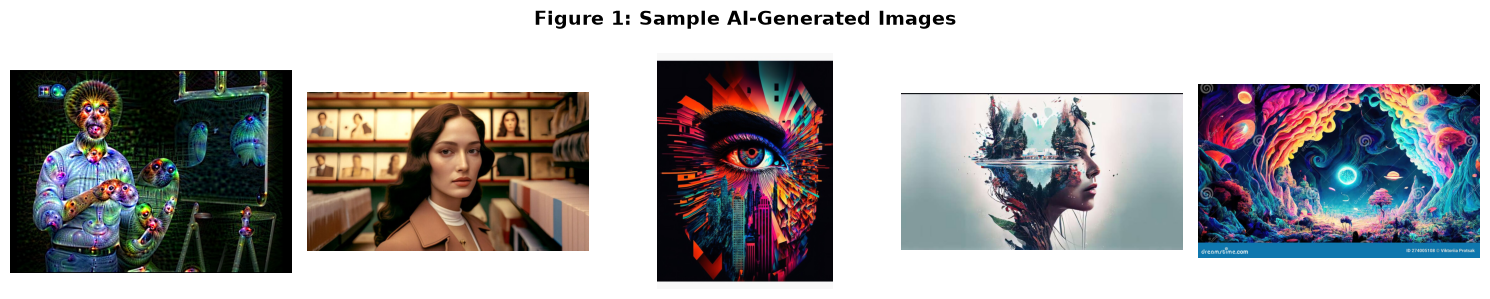

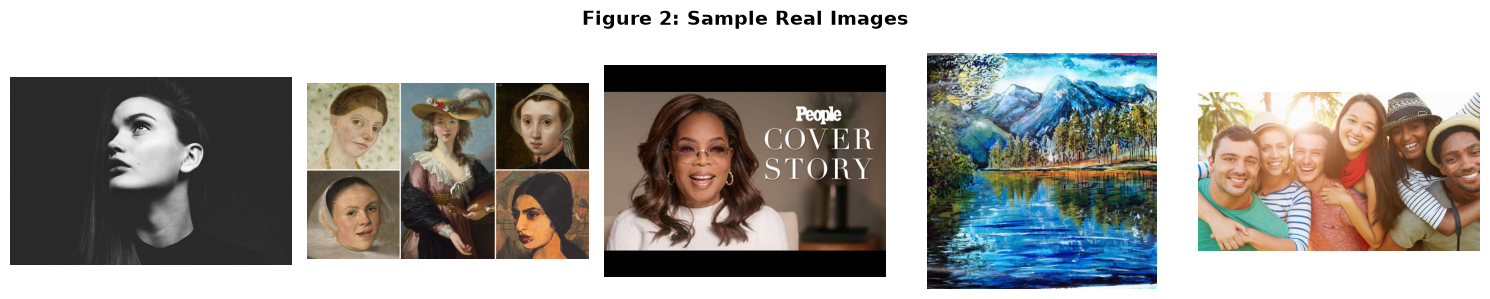

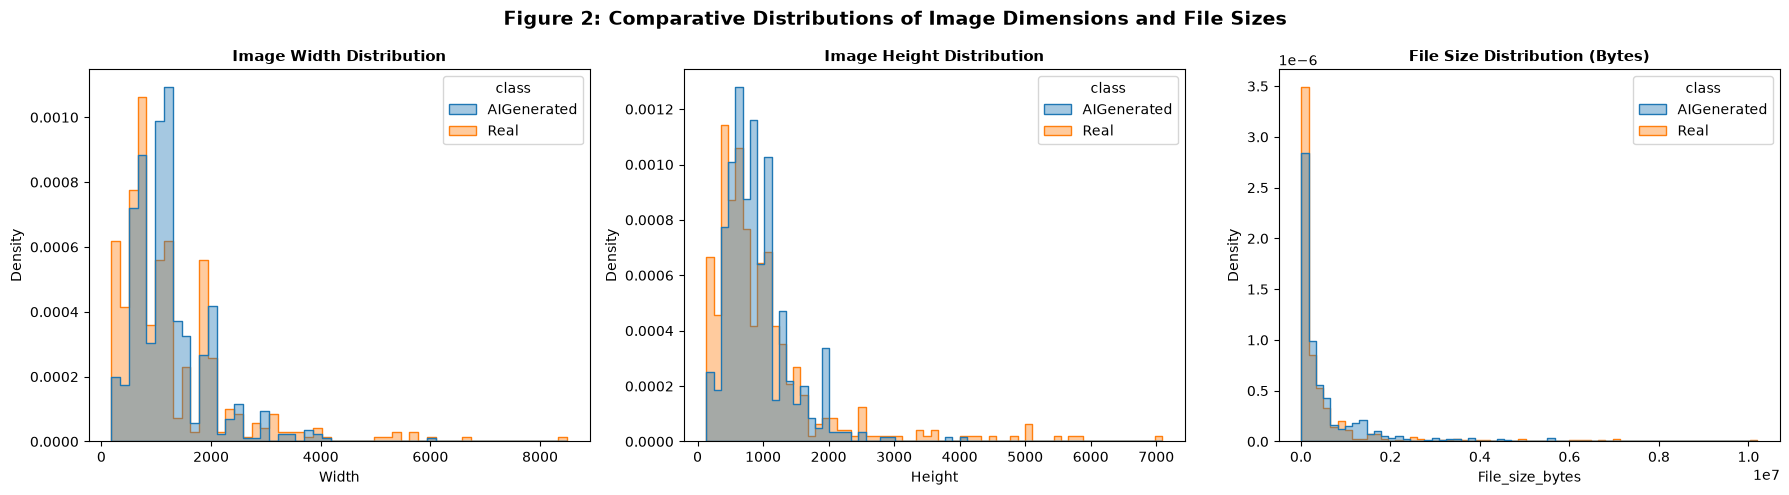

In [3]:
import os
import hashlib
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd

DATASET_DIRS = {
    "AIGenerated": "Data/AiArtData",
    "Real": "Data/RealArt"
}


data_list, corrupt_list=audit_dataset(DATASET_DIRS)
df=pd.DataFrame(data_list)
print(df['class'].value_counts())

for col in ['width', 'height', 'file_size_bytes']:
    print(f"{col.upper()} -> Min: {df[col].min()}, Median: {df[col].median()}, Max: {df[col].max()}")

print(f"\nTotal Corrupt Files: {len(corrupt_list)}")
duplicates_df = df[df.duplicated(subset=['sha256'], keep=False)]
print(f"Total Duplicate Files Found: {len(duplicates_df)}")

conflict = df.groupby("sha256")["class"].nunique()
conflict_hashes = conflict[conflict > 1].index
df_clean = df[~df["sha256"].isin(conflict_hashes)].drop_duplicates(subset=["sha256"], keep="first")
print(f"Rows before cleaning: {len(df)}, after: {len(df_clean)}")


plot_ai_sample_images(df_clean)
plot_real_sample_images(df_clean)
plot_feature_histograms(df_clean)

**Task 2**

In [4]:
import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32

def load_and_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label

def augment(image, label):                                  
    image = tf.image.random_flip_left_right(image)          
    image = tf.image.random_brightness(image, max_delta=25.0)
    image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
    image = tf.clip_by_value(image, 0.0, 255.0)             
    return image, label                                     

def make_dataset(paths, labels, training, augment_on=True):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(buffer_size=1000, seed=42, reshuffle_each_iteration=True)
    ds = ds.map(load_and_resize, num_parallel_calls=4)
    if training and augment_on:                          
        ds = ds.map(augment, num_parallel_calls=4)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(2)
    return ds

In [5]:
from sklearn.model_selection import train_test_split

paths = df_clean["file_path"].tolist()          
labels = df_clean["class"].map({"Real": 0, "AIGenerated": 1}).tolist()


train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    paths, labels,
    test_size=0.30,
    stratify=labels,
    random_state=42,
)


val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=42,
)

print("Train:", len(train_paths), "Val:", len(val_paths), "Test:", len(test_paths))
print("Train class counts:", train_labels.count(0), "Real,", train_labels.count(1), "AI")

Train: 681 Val: 146 Test: 147
Train class counts: 305 Real, 376 AI


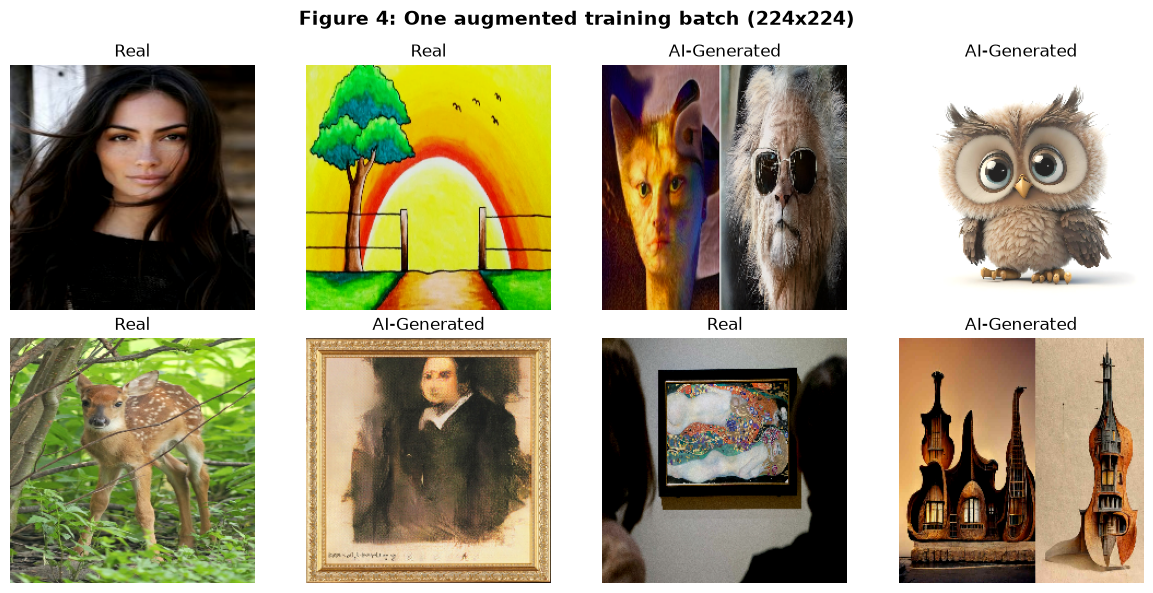

In [12]:
import matplotlib.pyplot as plt

class_names = {0: "Real", 1: "AI-Generated"}

train_ds = make_dataset(train_paths, train_labels, training=True)

for images, labels in train_ds.take(1):
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i, ax in enumerate(axes.flat):
        img = images[i].numpy().astype("uint8")
        ax.imshow(img)
        ax.set_title(class_names[int(labels[i])])
        ax.axis("off")

    fig.suptitle("Figure 4: One augmented training batch (224x224)",
                 fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig("augmented_batch.png", dpi=150)
    plt.show()

In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

def build_baseline_cnn(input_shape=(128, 128, 3)):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(32, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(64, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Conv2D(128, kernel_size=(3, 3), padding='same', activation='relu'),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        
        layers.Dense(1, activation='sigmoid')
    ], name="VisionGuard_Baseline_CNN")
    
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss=tf.keras.losses.BinaryCrossentropy(),
        metrics=[
            'accuracy', 
            tf.keras.metrics.Precision(name='precision'), 
            tf.keras.metrics.Recall(name='recall')
        ]
    )
    
    return model

model = build_baseline_cnn()
model.summary()

I0000 00:00:1793798736.147330   17455 gpu_device.cc:2042] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 8538 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5070, pci bus id: 0000:01:00.0, compute capability: 12.0a


Model: "VisionGuard_Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,289,217 (16.36 MB)

 Trainable params: 4,288,513 (16.36 MB)

 Non-trainable params: 704 (2.75 KB)

In [7]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models, optimizers, losses, metrics
from tensorflow.keras.callbacks import EarlyStopping

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds   = make_dataset(val_paths, val_labels, training=False)
test_ds  = make_dataset(test_paths, test_labels, training=False)

def build_transfer_model():
    base = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                       include_top=False, 
                       weights="imagenet")
    base.trainable = False                

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Lambda(preprocess_input, name="mobilenet_preprocess")(inputs)  
    x = base(x, training=False)                  
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="head")(x)
    model = models.Model(inputs, outputs, name="VisionGuard_MobileNetV2")
    return model, base

def compile_model(model, lr):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss=losses.BinaryCrossentropy(),
        metrics=["accuracy",
                 metrics.Precision(name="precision"),
                 metrics.Recall(name="recall")],
    )

model, base = build_transfer_model()
compile_model(model, lr=1e-3)
model.summary()

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)

Model: "VisionGuard_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess (Lambda)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head (Dense)                    │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10


... (22 outputs left out)

W0000 00:00:1793787044.854205   41602 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 171ms/step - accuracy: 0.8179 - loss: 0.4193 - precision: 0.8198 - recall: 0.8590 - val_accuracy: 0.7260 - val_loss: 0.5239 - val_precision: 0.7595 - val_recall: 0.7407
Epoch 10/10
16/22 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.7930 - loss: 0.4429 - precision: 0.8321 - recall: 0.7917

W0000 00:00:1793787050.363379   41716 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 162ms/step - accuracy: 0.7871 - loss: 0.4454 - precision: 0.7969 - recall: 0.8245 - val_accuracy: 0.7329 - val_loss: 0.5244 - val_precision: 0.7442 - val_recall: 0.7901


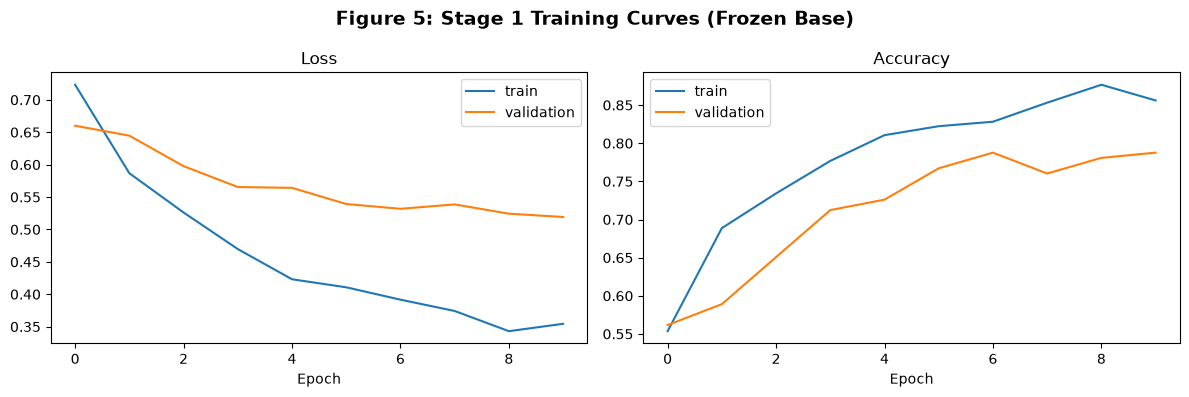


=== Stage 1: trainable layers ===
Base model (MobileNetV2):
  none (base is frozen)
Head:
  head (Dense)
Total trainable parameters: 1,281


In [ ]:
def plot_curves(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(history.history[metric], label="train")
        ax.plot(history.history[f"val_{metric}"], label="validation")
        ax.set_title(metric.capitalize())
        ax.set_xlabel("Epoch")
        ax.legend()
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"{title.replace(' ', '_').replace(':', '')}.png", dpi=150)
    plt.show()

def list_trainable_layers(model, base, stage_name):
    print(f"\n{stage_name}: trainable layers")
    print("Base model (MobileNetV2):")
    base_trainable = [l for l in base.layers if l.trainable_weights]
    if not base_trainable:
        print("  none (base is frozen)")
    for l in base_trainable:
        print(f"  {l.name} ({l.__class__.__name__})")
    print("Head:")
    for l in model.layers:
        if l.name in ("head",) or l.name.startswith("dropout") or l.name.startswith("global"):
            if l.trainable_weights:
                print(f"  {l.name} ({l.__class__.__name__})")
    total = sum(int(tf.size(w)) for w in model.trainable_weights)
    print(f"Total trainable parameters: {total:,}")

plot_curves(history_stage1, "Figure 5: Stage 1 Training Curves (Frozen Base)")
list_trainable_layers(model, base, "Stage 1")

In [ ]:
base.trainable = True
for layer in base.layers:
    is_last_block = layer.name.startswith("block_16") or layer.name in ("Conv_1", "out_relu")
    layer.trainable = is_last_block and not isinstance(layer, layers.BatchNormalization)

compile_model(model, lr=1e-5)

stage1_epochs = len(history_stage1.epoch)
history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=stage1_epochs,
    epochs=stage1_epochs + 10,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)],
)

Epoch 11/20
19/22 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.8914 - loss: 0.3163 - precision: 0.8944 - recall: 0.9104

W0000 00:00:1793525788.052956   38371 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 442ms/step - accuracy: 0.8796 - loss: 0.3278 - precision: 0.8868 - recall: 0.8963 - val_accuracy: 0.7877 - val_loss: 0.5145 - val_precision: 0.7660 - val_recall: 0.8889
Epoch 12/20
 4/22 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - accuracy: 0.8906 - loss: 0.3230 - precision: 0.8889 - recall: 0.9143

W0000 00:00:1793525795.444921   38737 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 192ms/step - accuracy: 0.9060 - loss: 0.2957 - precision: 0.9216 - recall: 0.9069 - val_accuracy: 0.7808 - val_loss: 0.5178 - val_precision: 0.7579 - val_recall: 0.8889
Epoch 13/20
17/22 ━━━━━━━━━━━━━━━━━━━━ 0s 163ms/step - accuracy: 0.9099 - loss: 0.2683 - precision: 0.8910 - recall: 0.9533

W0000 00:00:1793525801.825098   38806 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


... (9 outputs left out)

W0000 00:00:1793525820.331182   39182 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 190ms/step - accuracy: 0.9442 - loss: 0.1992 - precision: 0.9495 - recall: 0.9495 - val_accuracy: 0.7877 - val_loss: 0.5038 - val_precision: 0.7907 - val_recall: 0.8395
Epoch 19/20
 5/22 ━━━━━━━━━━━━━━━━━━━━ 3s 213ms/step - accuracy: 0.9625 - loss: 0.1805 - precision: 0.9647 - recall: 0.9647

W0000 00:00:1793525825.314076   39251 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 191ms/step - accuracy: 0.9589 - loss: 0.1777 - precision: 0.9603 - recall: 0.9654 - val_accuracy: 0.7945 - val_loss: 0.5314 - val_precision: 0.7684 - val_recall: 0.9012


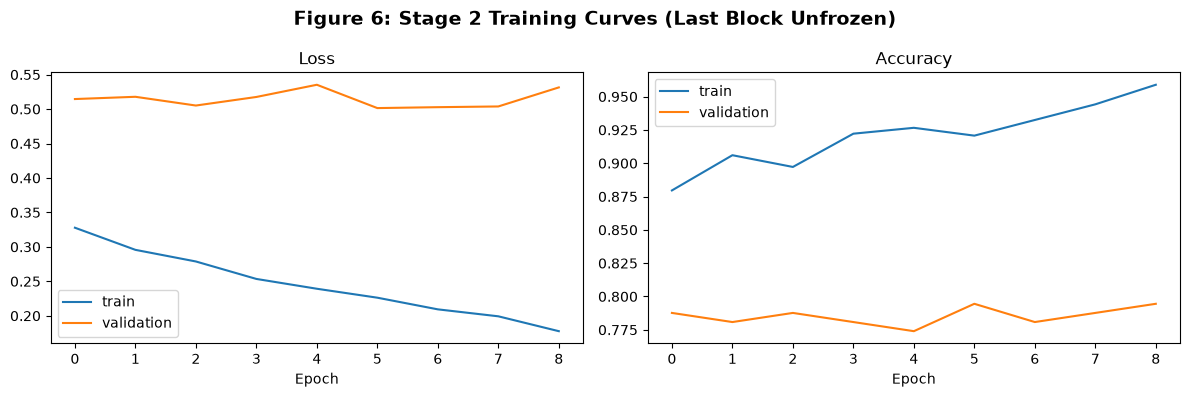


=== Stage 2: trainable layers ===
Base model (MobileNetV2):
  block_16_expand (Conv2D)
  block_16_depthwise (DepthwiseConv2D)
  block_16_project (Conv2D)
  Conv_1 (Conv2D)
Head:
  head (Dense)
Total trainable parameters: 880,321


In [13]:
plot_curves(history_stage2, "Figure 6: Stage 2 Training Curves (Last Block Unfrozen)")
list_trainable_layers(model, base, "Stage 2")

In [7]:
import numpy as np
import random
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

model, base = build_transfer_model()
compile_model(model, lr=1e-3)

ckpt_path = "best_stage1.keras"
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ModelCheckpoint(ckpt_path, monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6),
]
history_stage1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=callbacks)

best1 = int(np.argmin(history_stage1.history["val_loss"])) + 1
print(f"Stage 1 best epoch: {best1}")

Epoch 1/10
19/22 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5822 - loss: 0.7491 - precision: 0.6020 - recall: 0.7134

W0000 00:00:1793529009.634813   54243 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 12s 423ms/step - accuracy: 0.5888 - loss: 0.7418 - precision: 0.6101 - recall: 0.7074 - val_accuracy: 0.6712 - val_loss: 0.5952 - val_precision: 0.7200 - val_recall: 0.6667 - learning_rate: 0.0010
Epoch 2/10
 4/22 ━━━━━━━━━━━━━━━━━━━━ 2s 141ms/step - accuracy: 0.6328 - loss: 0.6502 - precision: 0.6716 - recall: 0.6429

W0000 00:00:1793529016.626189   54390 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 203ms/step - accuracy: 0.6902 - loss: 0.5846 - precision: 0.6978 - recall: 0.7739 - val_accuracy: 0.7123 - val_loss: 0.5722 - val_precision: 0.7097 - val_recall: 0.8148 - learning_rate: 0.0010
Epoch 3/10
17/22 ━━━━━━━━━━━━━━━━━━━━ 0s 164ms/step - accuracy: 0.7500 - loss: 0.5127 - precision: 0.7398 - recall: 0.8433

W0000 00:00:1793529023.241738   54470 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


... (11 outputs left out)

W0000 00:00:1793529047.711549   54931 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.8326 - loss: 0.3895 - precision: 0.8541 - recall: 0.8404 - val_accuracy: 0.7808 - val_loss: 0.5289 - val_precision: 0.7692 - val_recall: 0.8642 - learning_rate: 2.5000e-04
Epoch 10/10
 3/22 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.8438 - loss: 0.3855 - precision: 0.8361 - recall: 0.9107

W0000 00:00:1793529051.229281   55009 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 196ms/step - accuracy: 0.8370 - loss: 0.3922 - precision: 0.8354 - recall: 0.8777 - val_accuracy: 0.7808 - val_loss: 0.5265 - val_precision: 0.7692 - val_recall: 0.8642 - learning_rate: 1.2500e-04
Stage 1 best epoch: 8


In [8]:
base.trainable = True
for layer in base.layers:
    is_last_block = layer.name.startswith("block_16") or layer.name in ("Conv_1", "out_relu")
    layer.trainable = is_last_block and not isinstance(layer, layers.BatchNormalization)

compile_model(model, lr=1e-5)

ckpt_path2 = "best_stage2.keras"
callbacks2 = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ModelCheckpoint(ckpt_path2, monitor="val_loss", save_best_only=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-7),
]
stage1_epochs = len(history_stage1.epoch)
history_stage2 = model.fit(
    train_ds, validation_data=val_ds,
    initial_epoch=stage1_epochs, epochs=stage1_epochs + 10,
    callbacks=callbacks2,
)

best2 = int(np.argmin(history_stage2.history["val_loss"])) + 1 + stage1_epochs
print(f"Stage 2 best epoch (overall numbering): {best2}")

Epoch 11/20
 9/22 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.8472 - loss: 0.3864 - precision: 0.8805 - recall: 0.8485

W0000 00:00:1793529090.454175   55419 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 13s 445ms/step - accuracy: 0.8370 - loss: 0.3965 - precision: 0.8496 - recall: 0.8564 - val_accuracy: 0.7740 - val_loss: 0.5171 - val_precision: 0.8000 - val_recall: 0.7901 - learning_rate: 1.0000e-05
Epoch 12/20
 7/22 ━━━━━━━━━━━━━━━━━━━━ 2s 144ms/step - accuracy: 0.8661 - loss: 0.3622 - precision: 0.8762 - recall: 0.8440

W0000 00:00:1793529100.325479   55773 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 194ms/step - accuracy: 0.8620 - loss: 0.3461 - precision: 0.8730 - recall: 0.8777 - val_accuracy: 0.7877 - val_loss: 0.5222 - val_precision: 0.7660 - val_recall: 0.8889 - learning_rate: 1.0000e-05
Epoch 13/20
19/22 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.8717 - loss: 0.3306 - precision: 0.8824 - recall: 0.8876

W0000 00:00:1793529106.785021   55836 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


... (11 outputs left out)

W0000 00:00:1793529129.921077   56337 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 192ms/step - accuracy: 0.8972 - loss: 0.2882 - precision: 0.8923 - recall: 0.9255 - val_accuracy: 0.8151 - val_loss: 0.5036 - val_precision: 0.8000 - val_recall: 0.8889 - learning_rate: 2.5000e-06
Epoch 20/20
 1/22 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.9062 - loss: 0.2811 - precision: 0.9524 - recall: 0.9091

W0000 00:00:1793529134.057822   56401 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 210ms/step - accuracy: 0.9001 - loss: 0.2810 - precision: 0.9096 - recall: 0.9096 - val_accuracy: 0.8151 - val_loss: 0.5021 - val_precision: 0.8068 - val_recall: 0.8765 - learning_rate: 2.5000e-06
Stage 2 best epoch (overall numbering): 20


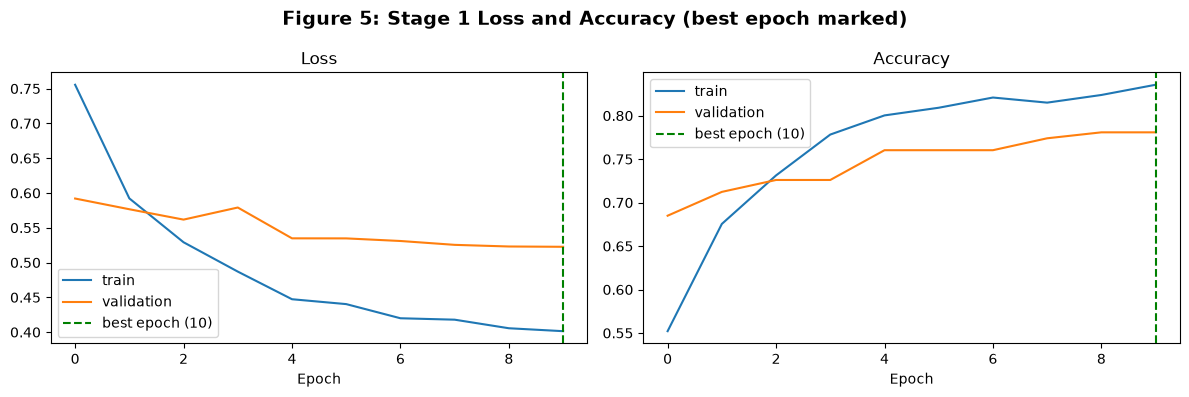

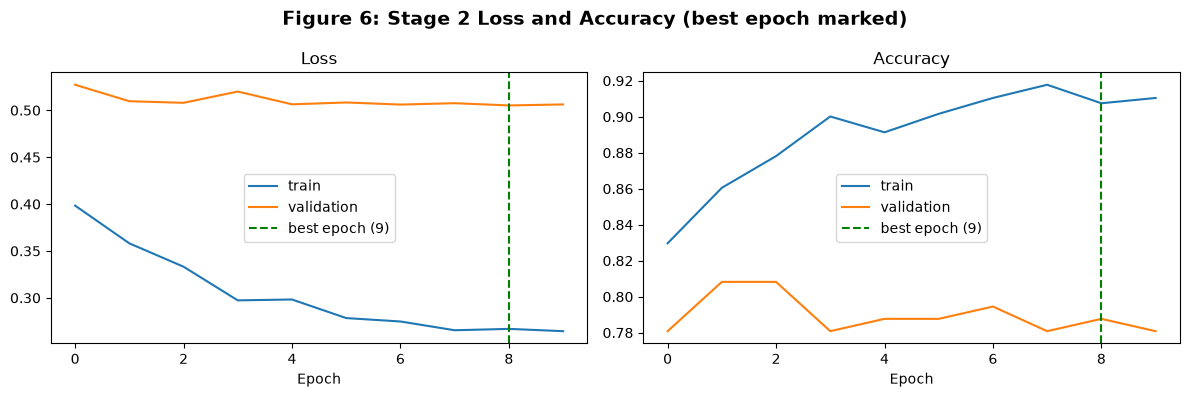

In [9]:
def plot_curves_marked(history, title, best_epoch_idx):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(history.history[metric], label="train")
        ax.plot(history.history[f"val_{metric}"], label="validation")
        ax.axvline(best_epoch_idx, color="green", linestyle="--", label=f"best epoch ({best_epoch_idx + 1})")
        ax.set_title(metric.capitalize())
        ax.set_xlabel("Epoch")
        ax.legend()
    fig.suptitle(title, fontsize=14, fontweight="bold")
    plt.tight_layout()
    plt.show()

plot_curves_marked(history_stage1, "Figure 5: Stage 1 Loss and Accuracy (best epoch marked)",
                   int(np.argmin(history_stage1.history["val_loss"])))
plot_curves_marked(history_stage2, "Figure 6: Stage 2 Loss and Accuracy (best epoch marked)",
                   int(np.argmin(history_stage2.history["val_loss"])))

In [9]:
baseline_model = build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3))
tf.keras.utils.set_random_seed(SEED)

history_base = baseline_model.fit(
    train_ds, validation_data=val_ds, epochs=30,
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
        ModelCheckpoint("best_baseline.keras", monitor="val_loss", save_best_only=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6),
    ],
)
print("Baseline best epoch:", int(np.argmin(history_base.history["val_loss"])) + 1)

Epoch 1/30


I0000 00:00:1793529175.142284   51512 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_72780__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.58
E0000 00:00:1793529175.568997   56590 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793529175.915037   56587 xtile_compiler.cc:399] Fusion: gemm_fusion_MatMul.8 = f32[64,128,32]{1,2,0} fusion(bitcast.2, bitcast.3), kind=kCustom, calls=gemm_fusion_MatMul.8_computation.clone, frontend_attributes={grad_x="false",grad_y="false"}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"8","output_tiles":[{"sizes":["1","128","32"]}],"num_ctas":1,"num_stages":3,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_

 8/22 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.5117 - loss: 1.0680 - precision: 0.5714 - recall: 0.5035

W0000 00:00:1793529180.458428   56568 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step - accuracy: 0.5685 - loss: 0.9147 - precision: 0.6289 - recall: 0.5376

I0000 00:00:1793529183.492922   51512 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_74534__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.65
E0000 00:00:1793529184.022947   56824 xtile_compiler.cc:399] Fusion: gemm_fusion_MatMul.8 = f32[16,128,9]{1,2,0} fusion(bitcast.2, bitcast.3), kind=kCustom, calls=gemm_fusion_MatMul.8_computation.clone, frontend_attributes={grad_x="false",grad_y="false"}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"2","output_tiles":[{"sizes":["1","32","16"]}],"num_ctas":1,"num_stages":3,"is_tma_allowed":true,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E0000 00:00:1793529184.022991   56824 xtile_compiler.cc:401] Computation: gemm_fusion_MatMul.8_computation.clone {
  parameter_

... (25 outputs left out)

W0000 00:00:1793529238.431815   58557 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 190ms/step - accuracy: 0.7974 - loss: 0.4152 - precision: 0.8020 - recall: 0.8404 - val_accuracy: 0.6438 - val_loss: 0.8105 - val_precision: 0.7544 - val_recall: 0.5309 - learning_rate: 1.2500e-04
Epoch 14/30
 2/22 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.9062 - loss: 0.3944 - precision: 0.9714 - recall: 0.8718 

W0000 00:00:1793529241.898966   58639 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 201ms/step - accuracy: 0.8355 - loss: 0.4050 - precision: 0.8529 - recall: 0.8484 - val_accuracy: 0.6233 - val_loss: 0.8452 - val_precision: 0.7321 - val_recall: 0.5062 - learning_rate: 6.2500e-05
Baseline best epoch: 9


Baseline CNN: threshold 0.66 | validation recall 0.148, FPR 0.092


E0000 00:00:1793529284.536072   58814 xtile_compiler.cc:399] Fusion: gemm_fusion_MatMul.4 = f32[64,128,19]{1,2,0} fusion(bitcast.2, bitcast.3), kind=kCustom, calls=gemm_fusion_MatMul.4_computation.clone, frontend_attributes={grad_x="false",grad_y="false"}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"4","output_tiles":[{"sizes":["1","128","32"]}],"num_ctas":1,"num_stages":3,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E0000 00:00:1793529284.536111   58814 xtile_compiler.cc:401] Computation: gemm_fusion_MatMul.4_computation.clone {
  parameter_1 = f32[64,1568,128]{2,1,0} parameter(1)
  parameter_0 = f32[19,64,1568]{2,1,0} parameter(0)
  ROOT dot = f32[64,128,19]{1,2,0} dot(parameter_1, parameter_0), lhs_batch_dims={0}, lhs_contracting_dims={1}, rhs_ba

MobileNetV2 transfer: threshold 0.88 | validation recall 0.444, FPR 0.092


E0000 00:00:1793529289.974713   59015 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793529290.179508   59021 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1793529290.360257   59011 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


                      Threshold  Accuracy  Precision  Recall      F1  ROC-AUC    TN   FP    FN    TP
Baseline CNN               0.66    0.5306     0.8333  0.1852  0.3030   0.7394  63.0  3.0  66.0  15.0
MobileNetV2 transfer       0.88    0.6531     0.9167  0.4074  0.5641   0.8515  63.0  3.0  48.0  33.0


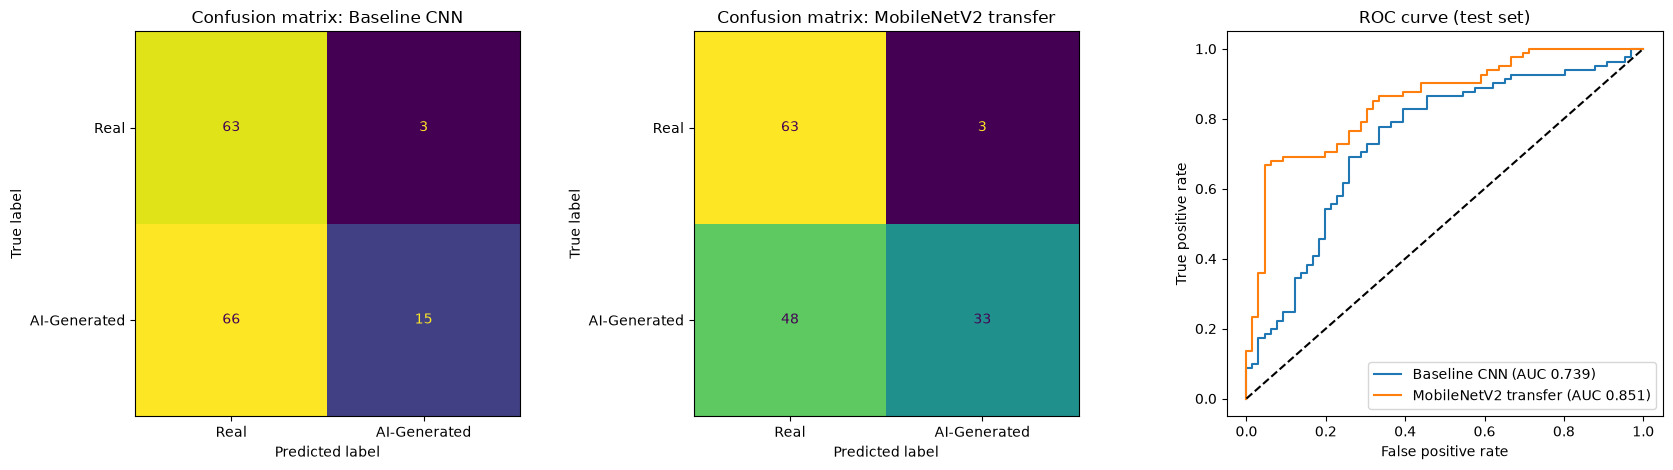

In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)

y_val = np.array(val_labels)
y_test = np.array(test_labels)

def get_probs(m, ds):
    return m.predict(ds, verbose=0).ravel()

def pick_threshold(y_true, p, max_fpr=0.10):
    ts = np.linspace(0.05, 0.95, 91)
    best = None
    for t in ts:
        pred = p >= t
        fp = np.sum(pred & (y_true == 0))
        neg = np.sum(y_true == 0)
        tp = np.sum(pred & (y_true == 1))
        pos = np.sum(y_true == 1)
        fpr, tpr = fp / neg, tp / pos
        if fpr <= max_fpr and (best is None or (tpr, t) > (best[1], best[0])):
            best = (t, tpr, fpr)
    return best

def test_metrics(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "Threshold": round(t, 2),
        "Accuracy": accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, p),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }, pred

models_to_eval = {"Baseline CNN": baseline_model, "MobileNetV2 transfer": model}
results, preds = {}, {}
for name, m in models_to_eval.items():
    t, val_tpr, val_fpr = pick_threshold(y_val, get_probs(m, val_ds))
    print(f"{name}: threshold {t:.2f} | validation recall {val_tpr:.3f}, FPR {val_fpr:.3f}")
    p_test = get_probs(m, test_ds)
    results[name], preds[name] = test_metrics(y_test, p_test, t)
    results[name]["_probs"] = p_test

table = pd.DataFrame({k: {kk: vv for kk, vv in v.items() if kk != "_probs"}
                      for k, v in results.items()}).T
print(table.round(4).to_string())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for i, name in enumerate(models_to_eval):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[name]),
                           display_labels=["Real", "AI-Generated"]).plot(ax=axes[i], colorbar=False)
    axes[i].set_title(f"Confusion matrix: {name}")
for name in models_to_eval:
    fpr, tpr, _ = roc_curve(y_test, results[name]["_probs"])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC {results[name]['ROC-AUC']:.3f})")
axes[2].plot([0, 1], [0, 1], "k--")
axes[2].set_xlabel("False positive rate")
axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curve (test set)")
axes[2].legend()
plt.tight_layout()
plt.savefig("evaluation_figures.png", dpi=150)
plt.show()

Misclassified: 51 (3 FP, 48 FN). Showing 10.


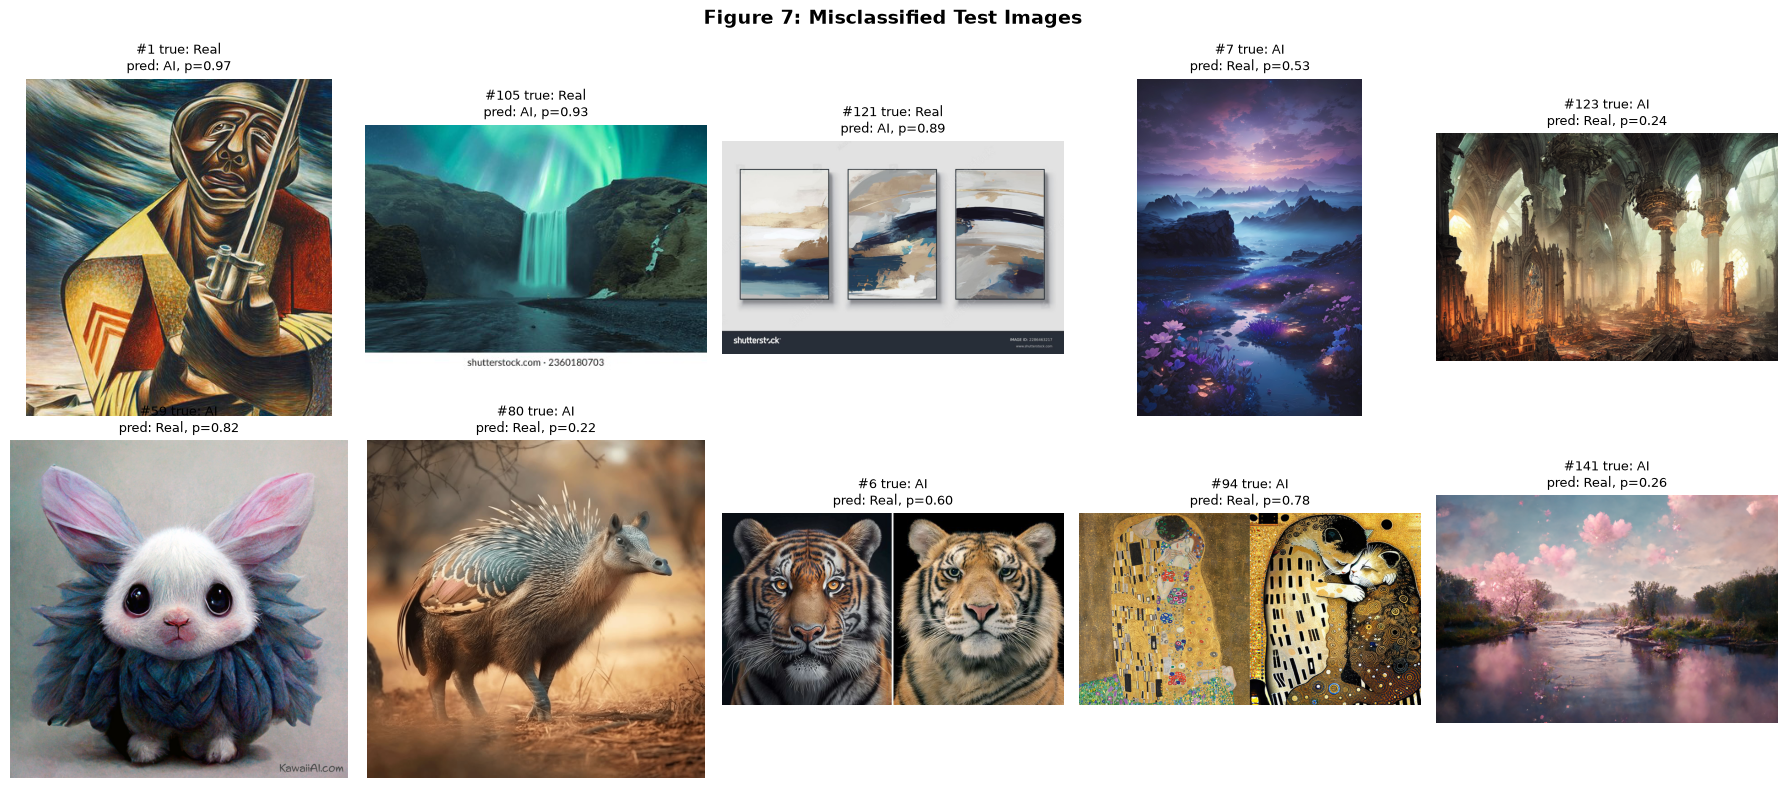

 idx true pred  prob      size mode format     KB                                                                             file
   1 Real   AI  0.97   362x400  RGB   JPEG   61.6                                                              1_Charles-White.jpg
 105 Real   AI  0.93   390x280  RGB   JPEG   25.2               picturesque-scenery-waterfall-flowing-through-260nw-2360180703.jpg
 121 Real   AI  0.89  1500x933  RGB   JPEG  101.0 ct-art-vector-illustrations-creative-minimalist-hand-drawn-vector-2286463217.jpg
   7   AI Real  0.53  853x1280  RGB   JPEG  242.8                                                    ai-generated-8247695_1280.jpg
 123   AI Real  0.24 2048x1365 RGBA    PNG 5486.7                                                             word-image-288-1.png
  59   AI Real  0.82 1500x1500  RGB   JPEG  588.4                                                         not-rabbit-not-mouse.jpg
  80   AI Real  0.22   750x750  RGB   JPEG  101.1                                  

In [11]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

test_probs = model.predict(test_ds, verbose=0).ravel()
y_test_arr = np.array(test_labels)
test_pred = (test_probs >= 0.88).astype(int)

wrong = np.where(test_pred != y_test_arr)[0]
fp_idx = [i for i in wrong if y_test_arr[i] == 0]
fn_idx = [i for i in wrong if y_test_arr[i] == 1]

rng = np.random.default_rng(42)
chosen = fp_idx + list(rng.choice(fn_idx, size=10 - len(fp_idx), replace=False))
print(f"Misclassified: {len(wrong)} ({len(fp_idx)} FP, {len(fn_idx)} FN). Showing {len(chosen)}.")

names = {0: "Real", 1: "AI"}
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, i in zip(axes.flat, chosen):
    ax.imshow(Image.open(test_paths[i]).convert("RGB"))
    ax.axis("off")
    ax.set_title(f"#{i} true: {names[y_test_arr[i]]}\npred: {names[test_pred[i]]}, p={test_probs[i]:.2f}",
                 fontsize=9)
fig.suptitle("Figure 7: Misclassified Test Images", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("error_analysis_grid.png", dpi=150)
plt.show()

rows = []
for i in chosen:
    im = Image.open(test_paths[i])
    rows.append({
        "idx": i,
        "true": names[y_test_arr[i]],
        "pred": names[test_pred[i]],
        "prob": round(float(test_probs[i]), 2),
        "size": f"{im.size[0]}x{im.size[1]}",
        "mode": im.mode,
        "format": im.format,
        "KB": round(os.path.getsize(test_paths[i]) / 1024, 1),
        "file": Path(test_paths[i]).name,
    })
print(pd.DataFrame(rows).to_string(index=False))

In [12]:
import keras_tuner as kt
import pandas as pd

(xf, yf), (xv, yv) = tf.keras.datasets.fashion_mnist.load_data()
xf, xv = xf / 255.0, xv / 255.0

def build_toy(hp):
    m = tf.keras.Sequential([
        tf.keras.layers.Input((28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(hp.Int("units", 32, 256, step=32), activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])
    m.compile(
        optimizer=tf.keras.optimizers.Adam(hp.Float("lr", 1e-4, 1e-2, sampling="log")),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return m

toy = kt.RandomSearch(build_toy, objective=kt.Objective("val_accuracy", "max"),
                      max_trials=6, directory="tuner_toy", project_name="fashion",
                      overwrite=True, seed=42)
toy.search(xf, yf, validation_data=(xv, yv), epochs=3, verbose=0)
print("Toy best:", toy.get_best_hyperparameters(1)[0].values)

I0000 00:00:1793531925.212316   51512 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_84874__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.12
I0000 00:00:1793531933.142716   51512 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_125474__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.12
I0000 00:00:1793531933.356680   63360 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_8', 20 bytes spill stores, 20 bytes spill loads

I0000 00:00:1793531940.938707   51512 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_166074__XlaMustCompile_true_config_proto_2201667018877855759_executor_type_11160318154034397263_.12
I0000 00:00:1793531948.797278   51512 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_206674__XlaMustCompile_true_config_pr

Toy best: {'units': 256, 'lr': 0.000505466655750672}


In [13]:
import keras_tuner as kt
import pandas as pd
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models, optimizers, losses
from tensorflow.keras.callbacks import EarlyStopping

def build_tuned(hp):
    base = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    n_unfrozen = hp.Int("unfrozen_layers", 0, 8, step=2)
    cutoff = len(base.layers) - n_unfrozen
    for i, layer in enumerate(base.layers):
        layer.trainable = (i >= cutoff) and not isinstance(layer, layers.BatchNormalization)

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Lambda(preprocess_input)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(hp.Float("dropout", 0.1, 0.5, step=0.1))(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    m = models.Model(inputs, outputs)
    m.compile(
        optimizer=optimizers.Adam(learning_rate=hp.Float("lr", 1e-5, 1e-3, sampling="log")),
        loss=losses.BinaryCrossentropy(),
        metrics=["accuracy"],
    )
    return m

tuner = kt.RandomSearch(build_tuned, objective=kt.Objective("val_loss", "min"),
                        max_trials=8, directory="tuner_visionguard",
                        project_name="transfer", overwrite=True, seed=42)
tuner.search(train_ds, validation_data=val_ds, epochs=6, verbose=0,
             callbacks=[EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)])

rows = [{**t.hyperparameters.values, "best_val_loss": round(t.score, 4)}
        for t in tuner.oracle.get_best_trials(num_trials=8)]
print(pd.DataFrame(rows).to_string())
print("VisionGuard best:", tuner.get_best_hyperparameters(1)[0].values)

/home/dragon/miniconda3/envs/ml_work/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1793531995.430910   65010 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
W0000 00:00:1793532006.065303   65212 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
W0000 00:00:1793532010.660774   65311 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
W0000 00:00:1793532016.101896   65392 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
W0000 00:00:1793532019.198985   65476 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid I

   unfrozen_layers  dropout        lr  best_val_loss
0                6      0.1  0.000066         0.4467
1                4      0.1  0.000099         0.4941
2                4      0.3  0.000068         0.5124
3                2      0.3  0.000718         0.5482
4                8      0.1  0.000855         0.5656
5                2      0.5  0.000172         0.6635
6                2      0.5  0.000051         0.7164
7                0      0.3  0.000028         0.7662
VisionGuard best: {'unfrozen_layers': 6, 'dropout': 0.1, 'lr': 6.562536901904111e-05}


**Task 3**

In [ ]:
#3.1 and 3.2

import mlflow
import mlflow.keras
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np


mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()


X_train = X_train[:1000] / 255.0
y_train = y_train[:1000]


mlflow.set_experiment("Task 3.1")


learning_rate = 0.001
epochs = 5
batch_size = 64

with mlflow.start_run():

    mlflow.log_param("learning_rate", learning_rate)
    mlflow.log_param("epochs", epochs)
    mlflow.log_param("batch_size", batch_size)
    mlflow.log_param("dataset", "MNIST subset")


    model = tf.keras.models.Sequential([
        tf.keras.layers.Flatten(input_shape=(28, 28)),
        tf.keras.layers.Dense(128, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(10, activation='softmax')
    ])

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])


    history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, verbose=1)


    for epoch in range(epochs):
        mlflow.log_metric("epoch_loss", history.history['loss'][epoch], step=epoch)
        mlflow.log_metric("epoch_accuracy", history.history['accuracy'][epoch], step=epoch)
        mlflow.log_metric("epoch_val_loss", history.history['val_loss'][epoch], step=epoch)
        mlflow.log_metric("epoch_val_accuracy", history.history['val_accuracy'][epoch], step=epoch)


    plt.figure(figsize=(8, 5))
    plt.plot(history.history['loss'], label='Train Loss', marker='o')
    plt.plot(history.history['val_loss'], label='Validation Loss', marker='x')
    plt.title(f"Training and Validation Loss (LR={learning_rate})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)
    
    plot_filename = "loss_curve.png"
    plt.savefig(plot_filename)
    mlflow.log_artifact(plot_filename)
    plt.close()

    mlflow.keras.log_model(model, "model")

    print("Run successfully completed, logged, and tracked!")

In [7]:
#3.3

import subprocess
import yaml
import tensorflow as tf
import mlflow
import dagshub
import mlflow.tensorflow

REPO_OWNER = "dragonibaad"
REPO_NAME = "VisionGuard"
dagshub.init(repo_owner=REPO_OWNER, repo_name=REPO_NAME, mlflow=True)
mlflow.set_experiment("VisionGuard-Task3.3")

SEED = 42
EPOCHS = 10
tf.keras.utils.set_random_seed(SEED)

def get_git_commit():
    return subprocess.check_output(["git", "rev-parse", "HEAD"]).decode().strip()

def get_dvc_data_version(dvc_file="Data.dvc"):
    with open(dvc_file) as f:
        info = yaml.safe_load(f)
    return info["outs"][0]["md5"]

def common_tags():
    return {
        "git_commit": get_git_commit(),
        "dvc_data_version": get_dvc_data_version(),
        "seed": str(SEED),
    }

/home/dragon/miniconda3/envs/ml_work/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Accessing as dragonibaad

Initialized MLflow to track repo "dragonibaad/VisionGuard"

Repository dragonibaad/VisionGuard initialized!

In [8]:
class MLflowEpochLogger(tf.keras.callbacks.Callback):    
    def on_epoch_end(self, epoch, logs=None):            
        mlflow.log_metrics({k: float(v) for k, v in logs.items()}, step=epoch)

In [12]:
test_ds = make_dataset(test_paths, test_labels, training=False)

tf.keras.utils.set_random_seed(SEED)                     # reset randomness so this run starts like the autolog run
model = build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3))
lr = float(tf.keras.backend.get_value(model.optimizer.learning_rate))

with mlflow.start_run(run_name="manual-callback"):
    mlflow.set_tags({**common_tags(), "approach": "manual"})
    mlflow.log_params({
        "img_size": 224,
        "batch_size": 32,
        "learning_rate": lr,
        "epochs": EPOCHS,
        "architecture": "baseline_cnn",
    })
    model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[MLflowEpochLogger()],
    )
    results = model.evaluate(test_ds, return_dict=True)
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in results.items()})

Epoch 1/10


/home/dragon/miniconda3/envs/ml_work/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793787439.455752   39737 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22119__.65
E0000 00:00:1793787439.865980   42333 xtile_compiler.cc:399] Fusion: gemm_fusion_MatMul.8 = f32[128,128,32]{1,2,0} fusion(bitcast.2, bitcast.3), kind=kCustom, calls=gemm_fusion_MatMul.8_computation.clone, frontend_attributes={grad_x="false",grad_y="false"}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"4","output_tiles":[{"sizes":["1","128","8"]}],"num_ctas":1,"num_stages":3,"is_tma_allowe

19/22 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step - accuracy: 0.5888 - loss: 0.9521 - precision: 0.6261 - recall: 0.6299

W0000 00:00:1793787445.433703   42306 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.5997 - loss: 0.9361 - precision: 0.6373 - recall: 0.6425

I0000 00:00:1793787446.190481   39738 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22119__.65
E0000 00:00:1793787446.507608   42583 xtile_compiler.cc:399] Fusion: gemm_fusion_MatMul.8 = f32[64,128,9]{1,2,0} fusion(bitcast.2, bitcast.3), kind=kCustom, calls=gemm_fusion_MatMul.8_computation.clone, frontend_attributes={grad_x="false",grad_y="false"}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"8","output_tiles":[{"sizes":["1","128","16"]}],"num_ctas":1,"num_stages":3,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E0000 00:00:1793787446.507633   42583 xtile_compiler.cc:401] Computation: gemm_fusion_MatMul.8_computation.clone {
  parameter_1 = f32[64,1568,128]{2,1,0} parameter(1)
  parameter_0 = f32[9,64,1568]{2,1,0} paramet

... (19 outputs left out)

W0000 00:00:1793787485.779756   43585 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 181ms/step - accuracy: 0.7621 - loss: 0.5080 - precision: 0.7688 - recall: 0.8138 - val_accuracy: 0.6096 - val_loss: 0.6738 - val_precision: 0.6500 - val_recall: 0.6420
4/5 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.6797 - loss: 0.6353 - precision: 0.6883 - recall: 0.7571

E0000 00:00:1793787489.989084   43686 xtile_compiler.cc:399] Fusion: gemm_fusion_MatMul.4 = f32[128,128,19]{1,2,0} fusion(bitcast.2, bitcast.3), kind=kCustom, calls=gemm_fusion_MatMul.4_computation.clone, frontend_attributes={grad_x="false",grad_y="false"}, backend_config={"operation_queue_id":"0","wait_on_operation_queues":[],"fusion_backend_config":{"kind":"__triton_nested_gemm_fusion","block_level_fusion_config":{"num_warps":"4","output_tiles":[{"sizes":["1","128","8"]}],"num_ctas":1,"num_stages":3,"is_tma_allowed":false,"is_warp_specialization_allowed":false}},"force_earliest_schedule":false,"reification_cost":[],"device_type":"DEVICE_TYPE_INVALID"}
E0000 00:00:1793787489.989116   43686 xtile_compiler.cc:401] Computation: gemm_fusion_MatMul.4_computation.clone {
  parameter_1 = f32[128,784,128]{2,1,0} parameter(1)
  parameter_0 = f32[19,128,784]{2,1,0} parameter(0)
  ROOT dot = f32[128,128,19]{1,2,0} dot(parameter_1, parameter_0), lhs_batch_dims={0}, lhs_contracting_dims={1}, rhs_b

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 258ms/step - accuracy: 0.6735 - loss: 0.6294 - precision: 0.6897 - recall: 0.7407
🏃 View run manual-callback at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1/runs/bf134af03e5a4c17b884686f01a71366
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1


In [15]:
mlflow.tensorflow.autolog(disable=True)

tf.keras.utils.set_random_seed(SEED)
model = build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3))

mlflow.tensorflow.autolog(log_models=False)
with mlflow.start_run(run_name="autolog"):
    mlflow.set_tags({**common_tags(), "approach": "autolog"})
    model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
    results = model.evaluate(test_ds, return_dict=True)
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in results.items()})

mlflow.tensorflow.autolog(disable=True)

2026/11/04 15:23:32 WARNING mlflow.utils.autologging_utils: MLflow tensorflow autologging is known to be compatible with 2.17.1 <= tensorflow, but the installed version is 2.22.0-dev0+selfbuilt. If you encounter errors during autologging, try upgrading / downgrading tensorflow to a compatible version, or try upgrading MLflow.
W0000 00:00:1793787823.653427   44369 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
W0000 00:00:1793787825.858020   44386 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
/home/dragon/miniconda3/envs/ml_work/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10


I0000 00:00:1793787832.534154   39737 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_30164__.65


 7/22 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.5714 - loss: 1.1605 - precision: 0.5556 - recall: 0.5963

W0000 00:00:1793787835.047399   44447 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.5952 - loss: 0.9203 - precision: 0.6452 - recall: 0.5930

... (20 outputs left out)

W0000 00:00:1793788190.368673   45530 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 170ms/step - accuracy: 0.7342 - loss: 0.5403 - precision: 0.7481 - recall: 0.7819 - val_accuracy: 0.5137 - val_loss: 1.2163 - val_precision: 0.7500 - val_recall: 0.1852
Epoch 10/10
 8/22 ━━━━━━━━━━━━━━━━━━━━ 2s 175ms/step - accuracy: 0.8047 - loss: 0.4724 - precision: 0.8000 - recall: 0.8671

W0000 00:00:1793788195.135510   45598 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 165ms/step - accuracy: 0.7621 - loss: 0.5245 - precision: 0.7772 - recall: 0.7979 - val_accuracy: 0.5616 - val_loss: 0.9741 - val_precision: 0.6889 - val_recall: 0.3827
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step - accuracy: 0.5578 - loss: 0.8148 - precision: 0.6905 - recall: 0.3580
🏃 View run autolog at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1/runs/49f90fbe583c4ba3a3ddd659b6c35831
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1


In [10]:
#3.4
import subprocess                                       
import numpy as np                                      
import pandas as pd                                     
import matplotlib.pyplot as plt                         
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

split_df = pd.DataFrame({                               
    "file_path": train_paths + val_paths + test_paths,
    "label": list(train_labels) + list(val_labels) + list(test_labels),
    "split": ["train"] * len(train_paths) + ["val"] * len(val_paths) + ["test"] * len(test_paths),
})
split_df.to_csv("split_lists.csv", index=False)         

with open("requirements.txt", "w") as f:                
    subprocess.run(["python", "-m", "pip", "freeze"], stdout=f, check=True)

print("Split rows:", len(split_df))                   

Split rows: 974


In [11]:
def attach_eval_artifacts(run_id, trained_model, tag):
    y_prob = trained_model.predict(test_ds).ravel()     
    y_true = np.array(test_labels)                      
    y_pred = (y_prob >= 0.5).astype(int)                

    
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 5))
    ConfusionMatrixDisplay(cm, display_labels=["Real", "AI-Generated"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix, test set ({tag})")
    cm_file = f"confusion_matrix_{tag}.png"
    plt.savefig(cm_file, dpi=150, bbox_inches="tight")
    plt.close(fig)

    
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    roc_auc = auc(fpr, tpr)                
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], "k--", label="Chance")
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curve, test set ({tag})")
    ax.legend()
    roc_file = f"roc_curve_{tag}.png"
    plt.savefig(roc_file, dpi=150, bbox_inches="tight")
    plt.close(fig)

    
    model_file = f"model_{tag}.keras"
    trained_model.save(model_file)

    
    with mlflow.start_run(run_id=run_id):
        mlflow.log_artifact(cm_file, artifact_path="evaluation")
        mlflow.log_artifact(roc_file, artifact_path="evaluation")
        mlflow.log_artifact(model_file, artifact_path="model")
        mlflow.log_metric("test_roc_auc", float(roc_auc))

    print(f"{tag}: test AUC = {roc_auc:.3f}")

In [ ]:
client = mlflow.tracking.MlflowClient()                  
exp = client.get_experiment_by_name("VisionGuard-Task3.3")

auto_run = client.search_runs(                           
    [exp.experiment_id],
    "tags.approach = 'autolog'",
    order_by=["attributes.start_time DESC"],             
)[0]

attach_eval_artifacts(auto_run.info.run_id, model, tag="autolog")

with mlflow.start_run(run_id=auto_run.info.run_id):
    mlflow.log_artifact("split_lists.csv", artifact_path="data")
    mlflow.log_artifact("requirements.txt", artifact_path="environment")

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step
🏃 View run autolog at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1/runs/49f90fbe583c4ba3a3ddd659b6c35831
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1
autolog: test AUC = 0.695
🏃 View run autolog at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1/runs/49f90fbe583c4ba3a3ddd659b6c35831
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1


In [13]:
client = mlflow.tracking.MlflowClient()
exp = client.get_experiment_by_name("VisionGuard-Task3.3")

In [ ]:
manual_run = client.search_runs(               
    [exp.experiment_id],
    "tags.approach = 'manual'",
    order_by=["attributes.start_time DESC"],
)[0]

attach_eval_artifacts(manual_run.info.run_id, model, tag="manual")

with mlflow.start_run(run_id=manual_run.info.run_id):
    mlflow.log_artifact("split_lists.csv", artifact_path="data")
    mlflow.log_artifact("requirements.txt", artifact_path="environment")

5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step
🏃 View run manual-callback at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1/runs/bf134af03e5a4c17b884686f01a71366
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1
manual: test AUC = 0.719
🏃 View run manual-callback at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1/runs/bf134af03e5a4c17b884686f01a71366
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/1


In [ ]:
#3.5

import numpy as np
from sklearn.metrics import roc_auc_score
from tensorflow.keras import layers, models, optimizers, losses, metrics
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping

mlflow.set_experiment("VisionGuard-Task3.5")             
client = mlflow.tracking.MlflowClient()                  
exp = client.get_experiment_by_name("VisionGuard-Task3.5")

def build_experiment_model(backbone, unfreeze_last=0):
    if backbone == "baseline":                           
        return build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False                               
    if unfreeze_last > 0:                                
        base.trainable = True
        for layer in base.layers[:-unfreeze_last]:
            layer.trainable = False
    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = layers.Lambda(preprocess_input)(inputs)          
    x = base(x, training=False)                          
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)   
    return models.Model(inputs, outputs)

def compile_experiment_model(model, lr):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=lr),
        loss=losses.BinaryCrossentropy(),
        metrics=["accuracy", metrics.Precision(name="precision"), metrics.Recall(name="recall")],
    )

def run_experiment(run_name, backbone, lr, augment_on, unfreeze_last=0):
    tf.keras.backend.clear_session()                     
    tf.keras.utils.set_random_seed(SEED)                 

    tr = make_dataset(train_paths, train_labels, training=True, augment_on=augment_on)
    va = make_dataset(val_paths, val_labels, training=False)
    te = make_dataset(test_paths, test_labels, training=False)

    model = build_experiment_model(backbone, unfreeze_last)
    compile_experiment_model(model, lr)
    trainable_params = int(sum(np.prod(v.shape) for v in model.trainable_weights))

    
    
    best_keeper = EarlyStopping(monitor="val_loss", patience=EPOCHS, restore_best_weights=True)

    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({**common_tags(), "approach": "experiment"})
        mlflow.log_params({
            "backbone": backbone,
            "learning_rate": lr,
            "augmentation": augment_on,
            "unfrozen_layers": unfreeze_last,
            "trainable_params": trainable_params,
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "epochs": EPOCHS,
        })
        history = model.fit(tr, validation_data=va, epochs=EPOCHS,
                            callbacks=[MLflowEpochLogger(), best_keeper], verbose=2)

        best_epoch = int(np.argmin(history.history["val_loss"])) + 1
        mlflow.log_param("best_epoch", best_epoch)       

        model.save(f"model_{run_name}.keras")            
        results = model.evaluate(te, return_dict=True)
        y_prob = model.predict(te, verbose=0).ravel()    
        y_true = np.array(test_labels)
        mlflow.log_metrics({f"test_{k}": float(v) for k, v in results.items()})
        mlflow.log_metric("test_roc_auc", float(roc_auc_score(y_true, y_prob)))

    tf.keras.backend.clear_session()                     

In [13]:
experiments = [
    dict(run_name="exp1-baseline",           backbone="baseline",  lr=1e-3, augment_on=True),
    dict(run_name="exp2-lr-1e-4",            backbone="baseline",  lr=1e-4, augment_on=True),
    dict(run_name="exp3-lr-1e-2",            backbone="baseline",  lr=1e-2, augment_on=True),
    dict(run_name="exp4-no-augmentation",    backbone="baseline",  lr=1e-3, augment_on=False),
    dict(run_name="exp5-mobilenet-frozen",   backbone="mobilenet", lr=1e-3, augment_on=True, unfreeze_last=0),
    dict(run_name="exp6-mobilenet-finetune", backbone="mobilenet", lr=1e-3, augment_on=True, unfreeze_last=30),
]

for cfg in experiments:
    print("Running", cfg["run_name"])
    run_experiment(**cfg)

Running exp1-baseline
Epoch 1/10


/home/dragon/miniconda3/envs/ml_work/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1793799721.405151   18846 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_76589__.65
W0000 00:00:1793799723.970411   27962 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space
I0000 00:00:1793799726.164294   18843 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_76589__.65


22/22 - 10s - 443ms/step - accuracy: 0.5859 - loss: 0.8593 - precision: 0.6320 - recall: 0.5984 - val_accuracy: 0.4726 - val_loss: 4.1373 - val_precision: 0.8333 - val_recall: 0.0617
Epoch 2/10


W0000 00:00:1793799730.505559   28111 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 - 4s - 180ms/step - accuracy: 0.6402 - loss: 0.7309 - precision: 0.6899 - recall: 0.6330 - val_accuracy: 0.4589 - val_loss: 0.9203 - val_precision: 0.5833 - val_recall: 0.0864
Epoch 3/10


W0000 00:00:1793799734.024295   28182 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


... (111 outputs left out)

W0000 00:00:1793800001.215964   33805 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 - 4s - 177ms/step - accuracy: 0.9559 - loss: 0.1105 - precision: 0.9482 - recall: 0.9734 - val_accuracy: 0.7466 - val_loss: 7.6685 - val_precision: 0.7037 - val_recall: 0.9383
Epoch 10/10


W0000 00:00:1793800003.322324   33885 png_io.cc:96] PNG warning: iCCP: profile 'ICC Profile': 'CMYK': invalid ICC profile color space


22/22 - 4s - 180ms/step - accuracy: 0.9736 - loss: 0.0765 - precision: 0.9864 - recall: 0.9654 - val_accuracy: 0.6712 - val_loss: 11.2901 - val_precision: 0.6387 - val_recall: 0.9383
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 339ms/step - accuracy: 0.7483 - loss: 1.6087 - precision: 0.7000 - recall: 0.9506
🏃 View run exp6-mobilenet-finetune at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/2/runs/f9ce985c34b64f4ab57d3bfc079a085d
🧪 View experiment at: https://dagshub.com/dragonibaad/VisionGuard.mlflow/#/experiments/2


                    run  backbone     lr augmentation  unfrozen  best_val_loss  test_accuracy  test_precision  test_recall  test_roc_auc
          exp1-baseline  baseline 0.0010         True         0         0.6184         0.7007          0.7229       0.7407        0.7288
           exp2-lr-1e-4  baseline 0.0001         True         0         0.8169         0.5374          0.8095       0.2099        0.7112
           exp3-lr-1e-2  baseline 0.0100         True         0         0.7122         0.6327          0.6452       0.7407        0.6902
   exp4-no-augmentation  baseline 0.0010        False         0         0.6853         0.6871          0.6966       0.7654        0.7376
  exp5-mobilenet-frozen mobilenet 0.0010         True         0         0.5196         0.7551          0.7647       0.8025        0.8393
exp6-mobilenet-finetune mobilenet 0.0010         True        30         2.1424         0.7483          0.7000       0.9506        0.8492


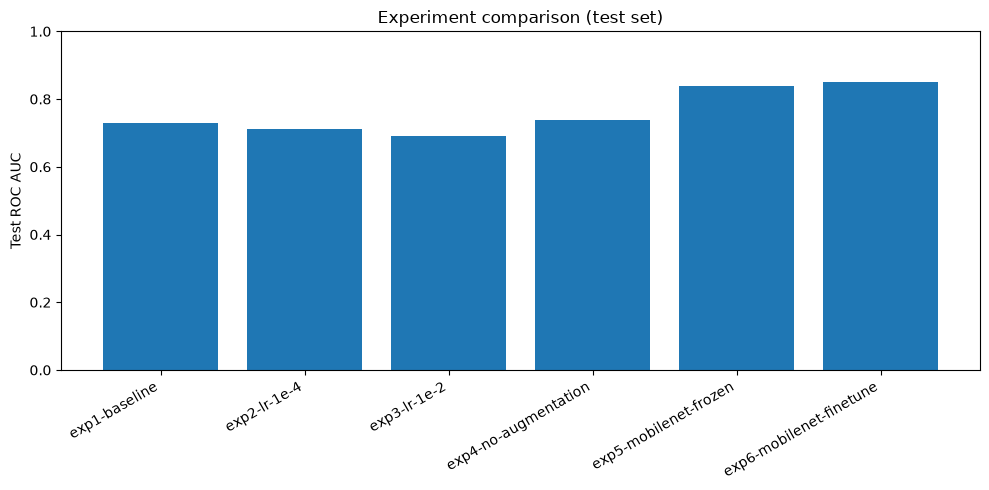

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

runs = client.search_runs([exp.experiment_id], "tags.approach = 'experiment'",
                          order_by=["attributes.start_time ASC"])
rows = []
for r in runs:
    val_hist = [m.value for m in client.get_metric_history(r.info.run_id, "val_loss")]
    rows.append({
        "run": r.info.run_name,
        "run_id": r.info.run_id,
        "backbone": r.data.params["backbone"],
        "lr": float(r.data.params["learning_rate"]),
        "augmentation": r.data.params["augmentation"],
        "unfrozen": int(r.data.params["unfrozen_layers"]),
        "best_val_loss": round(min(val_hist), 4),
        "test_accuracy": round(r.data.metrics["test_accuracy"], 4),
        "test_precision": round(r.data.metrics["test_precision"], 4),
        "test_recall": round(r.data.metrics["test_recall"], 4),
        "test_roc_auc": round(r.data.metrics["test_roc_auc"], 4),
    })
table = pd.DataFrame(rows)
print(table.drop(columns=["run_id"]).to_string(index=False))
table.to_csv("experiment_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(table["run"], table["test_roc_auc"])
ax.set_ylabel("Test ROC AUC")
ax.set_title("Experiment comparison (test set)")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("experiment_comparison.png", dpi=150)
plt.show()

In [ ]:
champion = table.loc[table["best_val_loss"].idxmin()]    
print("Champion:", champion["run"], "| best val loss:", champion["best_val_loss"])

with mlflow.start_run(run_id=champion["run_id"]):        
    mlflow.log_artifact(f"model_{champion['run']}.keras", artifact_path="model")
    mlflow.log_artifact("experiment_comparison.csv", artifact_path="comparison")
    mlflow.log_artifact("experiment_comparison.png", artifact_path="comparison")